# k_means


# 2. Zaimplementuj metodę k-means na podstawie wiadomości z wykładu.

In [75]:
import random
import numpy as np
from scipy.cluster.vq import vq
from sklearn import datasets
import scipy
from sklearn.metrics import jaccard_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, convex_hull_plot_2d
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn import preprocessing

In [76]:
def initial_centroids(X, k):
    initial = set()
    while len(initial) < k:
        initial.add(tuple(random.choice(X).tolist()))
    return np.array(list(initial))

def k_means(X, k, max_iterations=np.inf):

    centroids = initial_centroids(X, k)
    finished = False
    iteration = 0
    codes_prev = np.zeros(X.shape[0])
    while not finished and iteration < max_iterations:
        # Assign each vector to cluster
        codes, dists = vq(X, centroids)
    
        # Find new centroids
        for i in range(k):
            centroids[i, :] = np.mean(X[codes == i], axis=0)
            
        if (codes == codes_prev).all():
            finished = True
    
        codes_prev = codes
        iteration += 1
    return codes.astype("int32"), centroids

# 3. Testowanie metod klasteryzacji

3.1 Wczytaj daneirisoraz rozdziel je na cześć wejściową (X) i decyzje(Y).

In [77]:
iris = datasets.load_iris()
X = iris.data
Y = iris.target

3.2 Wykonaj klasteryzację przy pomocy własnej implementacji metod k-means.

In [78]:
Y_pred, centroids = k_means(X, 3)
Y_pred

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1], dtype=int32)

In [79]:
centroids

array([[6.85      , 3.07368421, 5.74210526, 2.07105263],
       [5.9016129 , 2.7483871 , 4.39354839, 1.43387097],
       [5.006     , 3.428     , 1.462     , 0.246     ]])

3.3 Poniższa funkcja wyszukuje najczęściej występującą wartość w Y_real pod kolejnymi indeksami
spełnianymi przez Y_pred. Dzięki temu wektorowi Y_pred przyporządkowuje się poprawne oznaczenia klas.

In [80]:
def find_perm(clusters, Y_real, Y_pred):
    perm=[]
    for i in range(clusters):
        idx = Y_pred == i
        new_label = scipy.stats.mode(Y_real[idx])[0][0]
        perm.append(new_label)
    return np.array([perm[label] for label in Y_pred])

Y_pred = find_perm(3, Y, Y_pred)
Y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 1, 1, 2, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 1])

In [81]:
# Pytanie.W jaki sposób działa powyższa funkcja.

# 4. Oblicz  indeks  Jaccarda  dla  danych  pogrupowanych  względem  klasydecyzyjnej (sklearn.metrics.jaccardscore).

**Indeks Jaccarda to statystyka do porównywania zbiorów. Mierzy podobieństwo między dwoma
zbiorami. Jest zdefiniowany jako iloraz mocy części wspólnej zbiorów i mocy sumy tych zbiorów :**  
**wartości bliskie 1 to ziory sa podobne**  
**wartości bliskie 0 to ziory sa różne**

In [82]:
jaccard_scores = {}
score = jaccard_score(Y, Y_pred, average=None)
jaccard_scores["kmeans"] = score
score

array([1.        , 0.75      , 0.69230769])

# 5. Zwizualizuj dane w przestrzeni 2D. Wizualizacji należy dokonać przypomocy metody PCA rzutując dane na dwie pierwsze składowe główne.

In [83]:
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

def plot_convex(data, y, ax):
    unique_labels = np.unique(y)
    for i in unique_labels:
        data_by_class = data[y == i, :]
        convex_hull = ConvexHull(data_by_class)
        for simplice in convex_hull.simplices:
            ax.plot(data_by_class[simplice, 0], data_by_class[simplice, 1], 'k')

Text(0.5, 1.0, 'Dane, które zostały poprawnie sklasyfiikowane, a które nie')

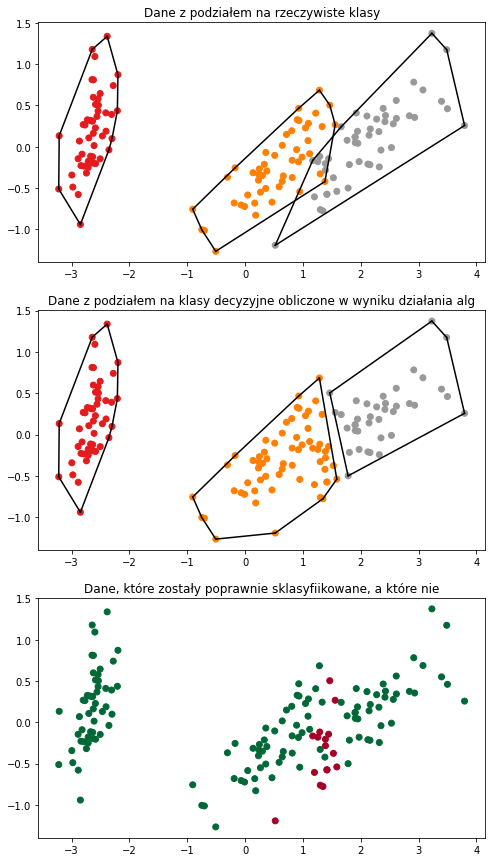

In [84]:
fig, axes = plt.subplots(3, 1, figsize=(8, 15))
axes[0].scatter(X_reduced[:, 0], X_reduced[:, 1], c=Y, cmap='Set1')
plot_convex(X_reduced, Y, axes[0])
axes[1].scatter(X_reduced[:, 0], X_reduced[:, 1], c=Y_pred, cmap='Set1')
plot_convex(X_reduced, Y_pred, axes[1])
axes[2].scatter(X_reduced[:, 0], X_reduced[:, 1], c=Y==Y_pred, cmap='RdYlGn')
axes[0].set_title("Dane z podziałem na rzeczywiste klasy")
axes[1].set_title("Dane z podziałem na klasy decyzyjne obliczone w wyniku działania alg")
axes[2].set_title("Dane, które zostały poprawnie sklasyfiikowane, a które nie")

# 6. Wizualizacja danych w przestrzeni 3D.

Text(0.5, 0.92, 'Dane, które zostały poprawnie sklasyfiikowane, a które nie')

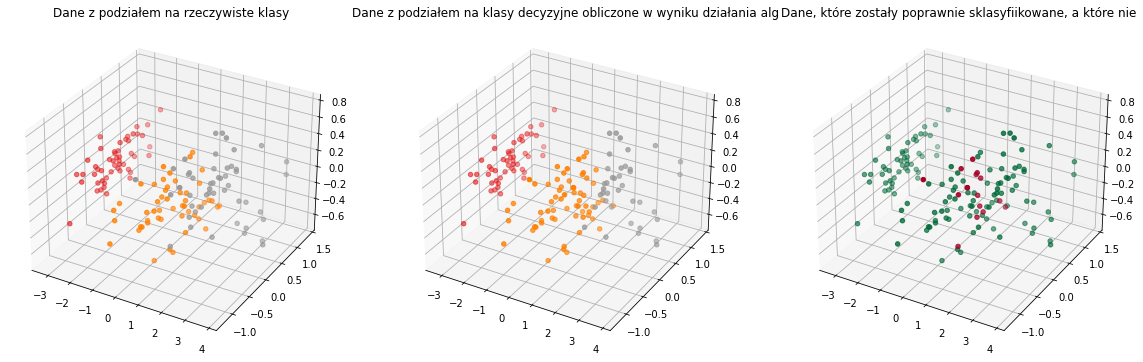

In [85]:
fig = plt.figure(figsize=(20, 20))
ax1 = fig.add_subplot(131, projection='3d')
ax2 = fig.add_subplot(132, projection='3d')
ax3 = fig.add_subplot(133, projection='3d')
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)
ax1.scatter(X_reduced[:, 0], X_reduced[:, 1], X_reduced[:, 2], c=Y, cmap='Set1')
ax2.scatter(X_reduced[:, 0], X_reduced[:, 1], X_reduced[:, 2], c=Y_pred, cmap='Set1')
ax3.scatter(X_reduced[:, 0], X_reduced[:, 1], X_reduced[:, 2], c=Y==Y_pred, cmap='RdYlGn')
ax1.set_title("Dane z podziałem na rzeczywiste klasy")
ax2.set_title("Dane z podziałem na klasy decyzyjne obliczone w wyniku działania alg")
ax3.set_title("Dane, które zostały poprawnie sklasyfiikowane, a które nie")

# 7. Powtórz zadania 3 – 6 dla następujących metod: 

In [86]:
def plot_reduction(X, Y, Y_pred):
    pca = PCA(n_components=2)
    X_reduced = pca.fit_transform(X)

    fig = plt.figure(figsize=(20, 20))

    ax1 = fig.add_subplot(321)
    ax2 = fig.add_subplot(323)
    ax3 = fig.add_subplot(325)
    ax1.scatter(X_reduced[:, 0], X_reduced[:, 1], c=Y, cmap='Set1')
    plot_convex(X_reduced, Y, ax1)
    ax2.scatter(X_reduced[:, 0], X_reduced[:, 1], c=Y_pred, cmap='Set1')
    plot_convex(X_reduced, Y_pred, ax2)
    ax3.scatter(X_reduced[:, 0], X_reduced[:, 1], c=Y==Y_pred, cmap='RdYlGn')
    ax1.set_title("Dane z podziałem na rzeczywiste klasy")
    ax2.set_title("Dane z podziałem na klasy decyzyjne obliczone w wyniku działania alg")
    ax3.set_title("Dane, które zostały poprawnie sklasyfiikowane, a które nie")

    ax4 = fig.add_subplot(322, projection='3d')
    ax5 = fig.add_subplot(324, projection='3d')
    ax6 = fig.add_subplot(326, projection='3d')
    pca = PCA(n_components=3)
    X_reduced = pca.fit_transform(X)
    ax4.scatter(X_reduced[:, 0], X_reduced[:, 1], X_reduced[:, 2], c=Y, cmap='Set1')
    ax5.scatter(X_reduced[:, 0], X_reduced[:, 1], X_reduced[:, 2], c=Y_pred, cmap='Set1')
    ax6.scatter(X_reduced[:, 0], X_reduced[:, 1], X_reduced[:, 2], c=Y==Y_pred, cmap='RdYlGn')
    ax4.set_title("Dane z podziałem na rzeczywiste klasy")
    ax5.set_title("Dane z podziałem na klasy decyzyjne obliczone w wyniku działania alg")
    ax6.set_title("Dane, które zostały poprawnie sklasyfiikowane, a które nie")

7.1 k_means

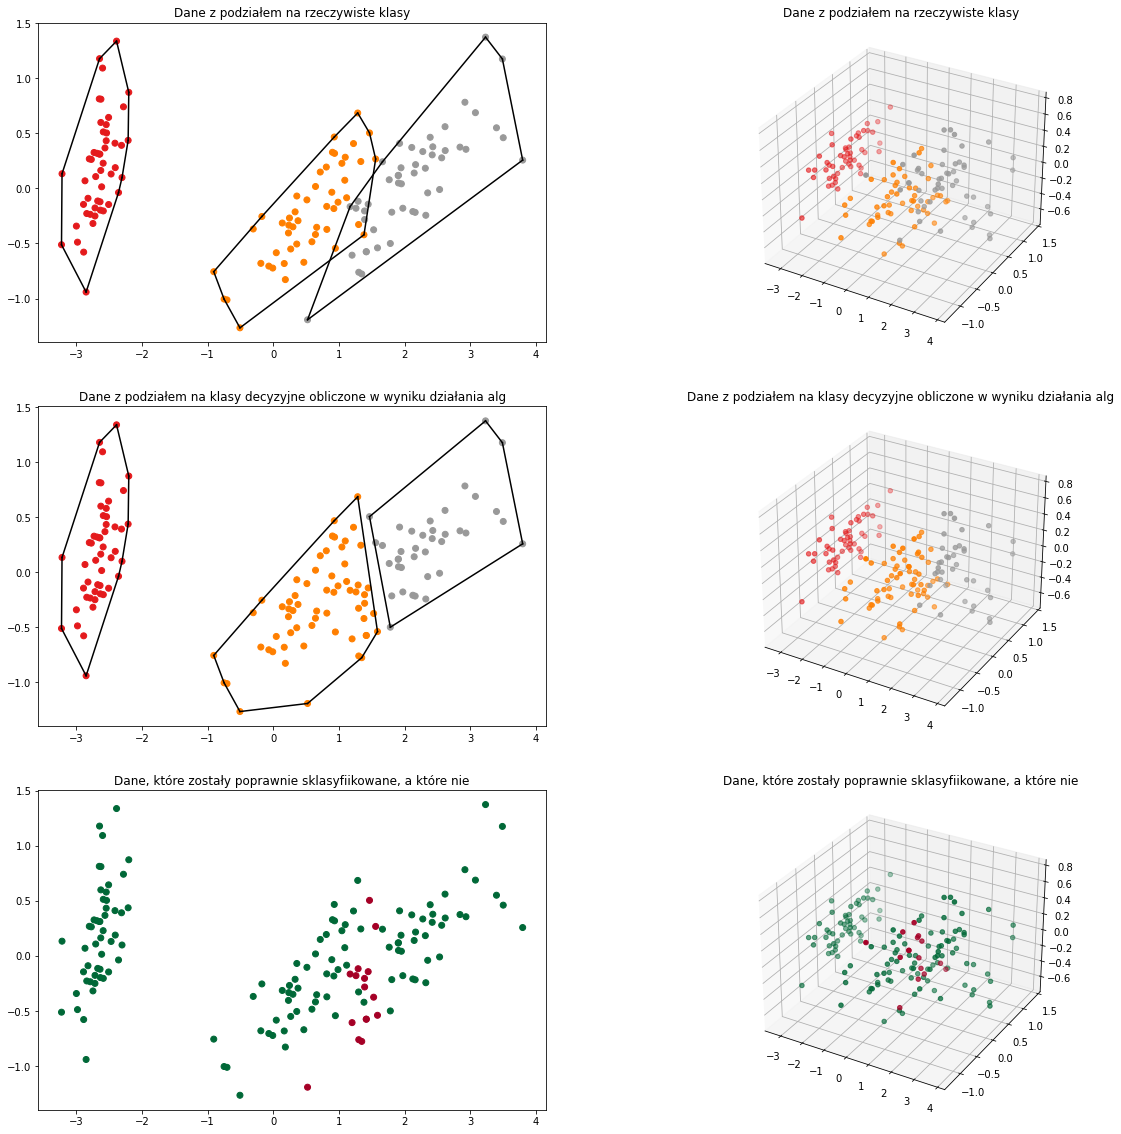

In [87]:
iris = datasets.load_iris()
X = iris.data
Y = iris.target
km = KMeans(n_clusters=3, random_state=0).fit(X)
Y_pred = km.predict(X)
Y_pred = find_perm(3, Y, Y_pred)
jaccard_scores["kmeans_sklearn"] = jaccard_score(Y, Y_pred, average=None)
plot_reduction(X, Y, Y_pred)

7.2 GMM

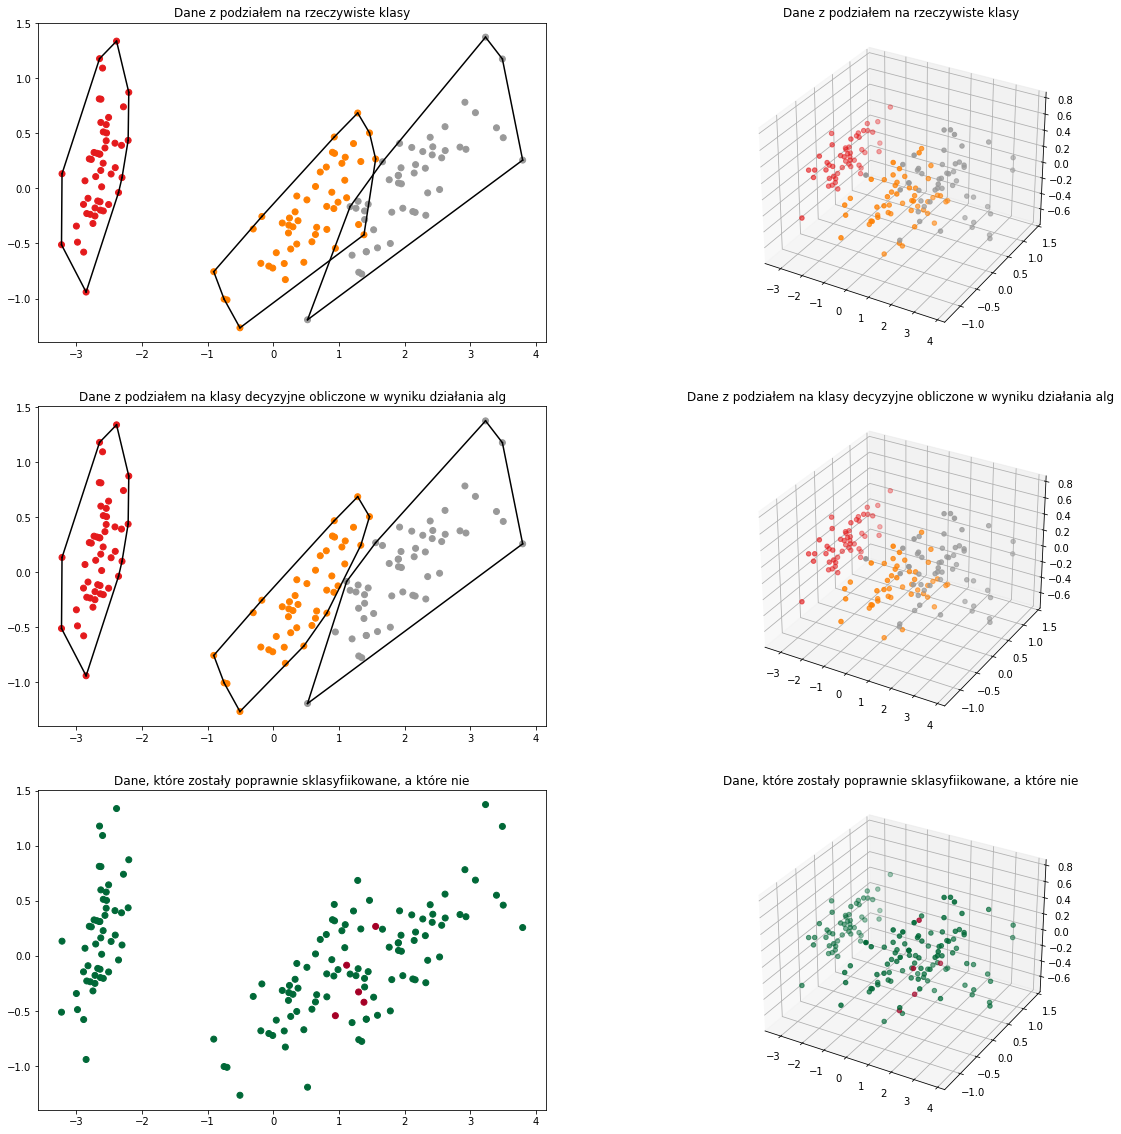

In [88]:
 from sklearn.mixture import GaussianMixture
iris = datasets.load_iris()
X = iris.data
Y = iris.target
7
gm = GaussianMixture(n_components=3).fit(X)
Y_pred = gm.predict(X)
Y_pred = find_perm(3, Y, Y_pred)
jaccard_scores["gmm_sklearn"] = jaccard_score(Y, Y_pred, average=None)
plot_reduction(X, Y, Y_pred)

7.3 AgglomerativeClustering

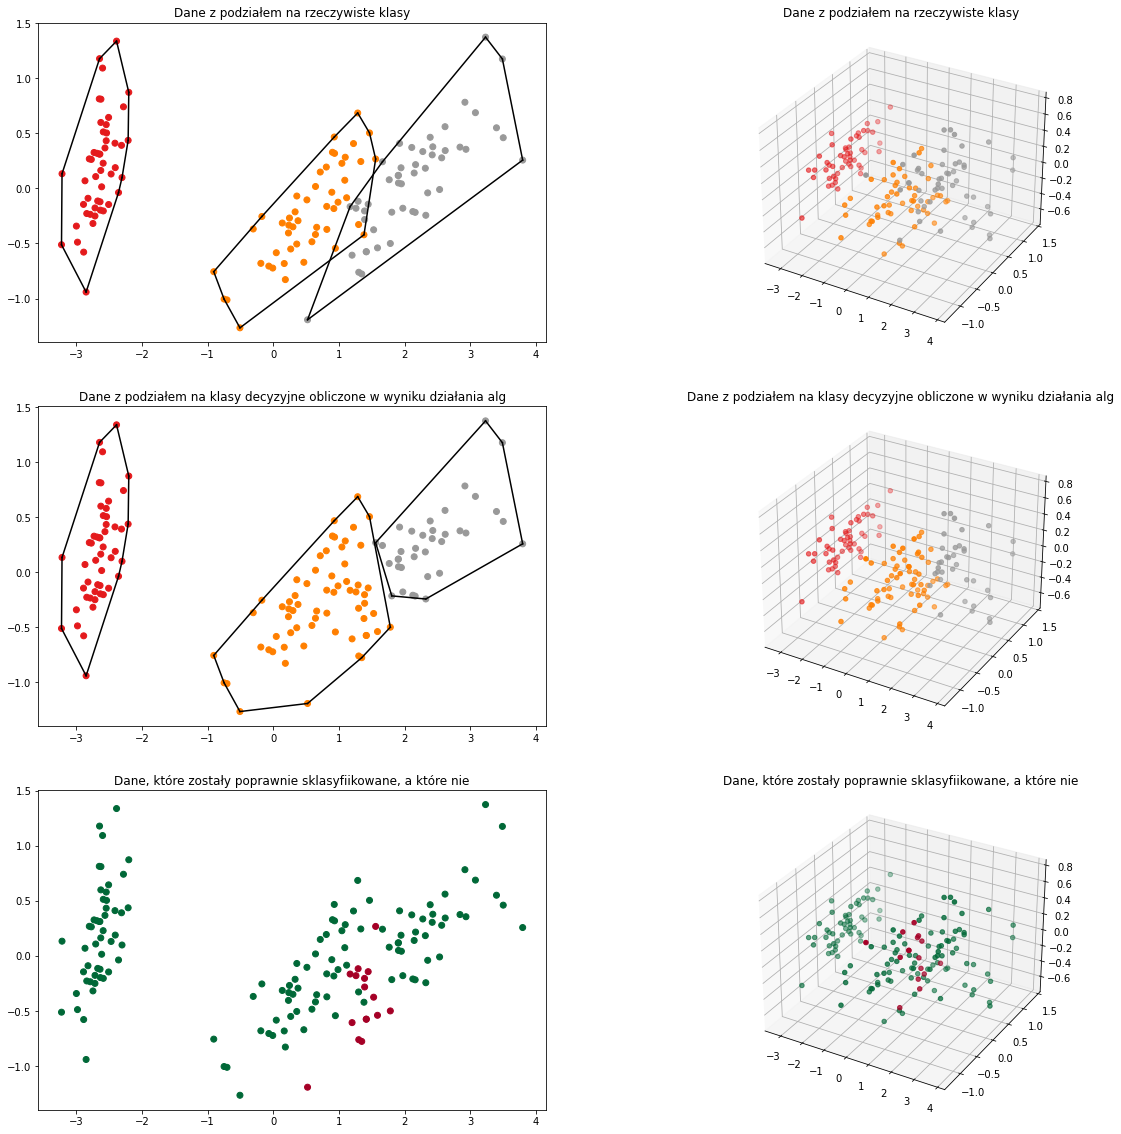

In [89]:
from sklearn.cluster import AgglomerativeClustering
linkages = ["complete", "average", "single", "ward"]
iris = datasets.load_iris()
X = iris.data
Y = iris.target
for linkage in linkages:
    model = AgglomerativeClustering(n_clusters=3, linkage=linkage).fit(X)
    Y_pred = model.labels_
    Y_pred = find_perm(3, Y, Y_pred)
    jaccard_scores["agglomerative_"+linkage] = jaccard_score(Y, Y_pred, average=None)
plot_reduction(X, Y, Y_pred)

7.4 Dendrogram

In [90]:
from scipy.cluster.hierarchy import dendrogram

def plot_dendrogram(model, **kwargs):

    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1 # leaf node
            else:
                current_count += counts[child_idx - n_samples]

            counts[i] = current_count
        linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)
        # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

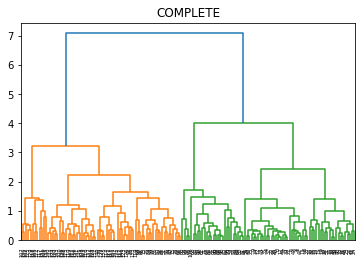

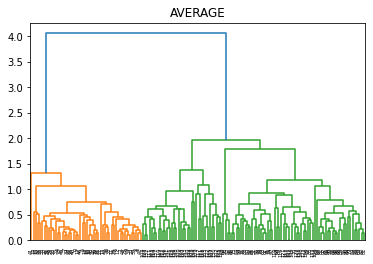

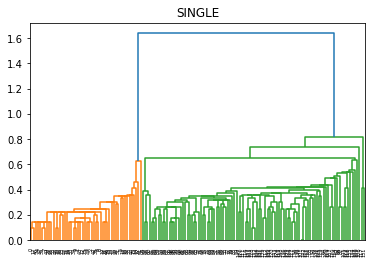

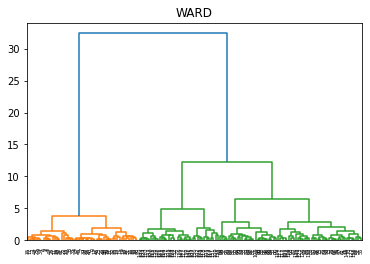

In [91]:
model = AgglomerativeClustering(n_clusters=None, distance_threshold=0, linkage='complete').fit(X)
plt.title('COMPLETE')
plot_dendrogram(model, truncate_mode='level')
plt.show()
model = AgglomerativeClustering(n_clusters=None, distance_threshold=0, linkage='average').fit(X)
plt.title('AVERAGE')
plot_dendrogram(model, truncate_mode='level')
plt.show()
model = AgglomerativeClustering(n_clusters=None, distance_threshold=0, linkage='single').fit(X)
plt.title('SINGLE')
plot_dendrogram(model, truncate_mode='level')
plt.show()
model = AgglomerativeClustering(n_clusters=None, distance_threshold=0, linkage='ward').fit(X)
plt.title('WARD')
plot_dendrogram(model, truncate_mode='level')
plt.show()

In [92]:
                           klasa_1 klasa_2 klasa_3
gmm_sklearn               1.000000 0.900000 0.909091
agglomerative_average     1.000000 0.781250 0.720000
agglomerative_ward        1.000000 0.753846 0.686275
kmeans_sklearn            1.000000 0.750000 0.692308
agglomerative_complete    1.000000 0.529412 0.671233
agglomerative_single      1.000000 0.510204 0.040000
kmeans                    0.925926 0.000000 0.520833

SyntaxError: invalid syntax (<ipython-input-92-67805d395880>, line 1)

# 8. Powtórzyć działania dla zbioru zoo.csv

In [95]:
df = pd.read_csv('/zoo.csv')
Y = df['type']
le = preprocessing.LabelEncoder()
Y = le.fit_transform(Y)
X = df.drop(columns=['animal', 'type']).to_numpy().astype('int')

NameError: name 'pd' is not defined